# ArcFace Model Conversion and Face Verification

This notebook examines an ArcFace IR-SE model from two practical perspectives:

1. **Model conversion and numerical consistency** — replace selected layers with deployment-friendly equivalents and verify that their outputs remain consistent.
2. **Face embedding and verification** — extract L2-normalized face embeddings from LFW, evaluate same/different identity verification, and inspect cosine-similarity-based retrieval.

The final sections export the converted model to ONNX and prepare ENLIGHT calibration / validation inputs for deployment-oriented testing.

In [ ]:
%pip -q install faiss-cpu onnx onnxruntime


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 33.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 48.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 34.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 13.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 7.36.2 which is incompatible.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 7.36.2 which is incompatible.


In [ ]:
from collections import namedtuple, Counter
from copy import deepcopy
from pathlib import Path
import pickle
import zipfile

import cv2
import faiss
import numpy as np
import plotly.express as px
import torch
from torch import nn
import torch.nn.functional as F
from torchvision import transforms
from sklearn.manifold import TSNE
from sklearn.model_selection import KFold
from google.colab import drive

drive.mount('/content/gdrive')
base_dir = Path('/content/gdrive/MyDrive/Face Detection and Recognition with NPU')
checkpoint_path = base_dir / 'model_ir_se50.pth'
webface_zip_path = base_dir / 'faces_webface_112x112.zip'
lfw_bin_path = Path('/content/faces_webface_112x112/lfw.bin')
output_dir = Path('/content/arcface_test')
output_dir.mkdir(parents=True, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
COLOR_ORDER = 'BGR'  # 기존 노트북의 OpenCV 디코딩 입력을 유지. 학습 시 RGB였다면 'RGB'로 변경.
QUICK_PAIRS = 16    # 먼저 16쌍(32장)으로 빠르게 테스트합니다.
RUN_FULL_LFW = False   # True이면 전체 LFW 10-fold verification 수행
RUN_ONNX = True
RUN_NETRON = False
BATCH_SIZE = 16
print('device:', device, '| color order:', COLOR_ORDER)


Mounted at /content/gdrive
device: cpu | color order: BGR


## 1. Load ArcFace IR-SE Model

In [ ]:
class Bottleneck(namedtuple('Block', ['in_channel', 'depth', 'stride'])):
    pass


def get_block(in_channel, depth, num_units, stride=2):
    return [Bottleneck(in_channel, depth, stride)] + [
        Bottleneck(depth, depth, 1) for _ in range(num_units - 1)
    ]


def get_blocks(num_layers):
    sizes = {50: (3, 4, 14, 3), 100: (3, 13, 30, 3), 152: (3, 8, 36, 3)}
    if num_layers not in sizes:
        raise ValueError(f'Unsupported depth: {num_layers}')
    return [get_block(in_ch, out_ch, count) for (in_ch, out_ch), count in zip(
        ((64, 64), (64, 128), (128, 256), (256, 512)), sizes[num_layers]
    )]


class SEModule(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc1 = nn.Conv2d(channels, channels // reduction, 1, bias=False)
        self.relu = nn.ReLU(inplace=False)
        self.fc2 = nn.Conv2d(channels // reduction, channels, 1, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        gate = self.sigmoid(self.fc2(self.relu(self.fc1(self.avg_pool(x)))))
        return x * gate


class bottleneck_IR_SE(nn.Module):
    def __init__(self, in_channel, depth, stride):
        super().__init__()
        if in_channel == depth:
            self.shortcut_layer = nn.MaxPool2d(kernel_size=1, stride=stride)
        else:
            self.shortcut_layer = nn.Sequential(
                nn.Conv2d(in_channel, depth, 1, stride=stride, bias=False),
                nn.BatchNorm2d(depth),
            )
        self.res_layer = nn.Sequential(
            nn.BatchNorm2d(in_channel),
            nn.Conv2d(in_channel, depth, 3, padding=1, bias=False),
            nn.PReLU(depth),
            nn.Conv2d(depth, depth, 3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(depth),
            SEModule(depth, 16),
        )

    def forward(self, x):
        return self.res_layer(x) + self.shortcut_layer(x)


class Backbone(nn.Module):
    def __init__(self, input_size=112, num_layers=50, drop_ratio=0.6, affine=True):
        super().__init__()
        if input_size not in (112, 224):
            raise ValueError('input_size must be 112 or 224')
        spatial = 7 if input_size == 112 else 14
        self.input_layer = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64), nn.PReLU(64),
        )
        self.body = nn.Sequential(*(
            bottleneck_IR_SE(b.in_channel, b.depth, b.stride)
            for block in get_blocks(num_layers) for b in block
        ))
        self.output_layer = nn.Sequential(
            nn.BatchNorm2d(512), nn.Dropout(drop_ratio), nn.Flatten(),
            nn.Linear(512 * spatial * spatial, 512),
            nn.BatchNorm1d(512, affine=affine),
        )

    def forward(self, x):
        return self.output_layer(self.body(self.input_layer(x)))


# 반드시 변환 전 baseline을 먼저 엄격하게 로드합니다.
if not checkpoint_path.is_file():
    raise FileNotFoundError(f'체크포인트를 찾지 못했습니다: {checkpoint_path}')
checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
if isinstance(checkpoint, dict) and isinstance(checkpoint.get('state_dict'), dict):
    checkpoint = checkpoint['state_dict']
if not isinstance(checkpoint, dict):
    raise TypeError('state_dict 형식의 체크포인트가 필요합니다.')
if checkpoint and all(k.startswith('module.') for k in checkpoint):
    checkpoint = {k.removeprefix('module.'): value for k, value in checkpoint.items()}
affine = 'output_layer.4.weight' in checkpoint
baseline_model = Backbone(112, 50, affine=affine)
baseline_model.load_state_dict(checkpoint, strict=True)
baseline_model = baseline_model.to(device).eval()
del checkpoint
print('Baseline checkpoint loaded (strict=True); BN1d affine:', affine)


Baseline checkpoint loaded (strict=True); BN1d affine: True


In [ ]:
# 정확한 변환은 shortcut 1x1 MaxPool 및 Flatten/Linear/BN1d에만 적용합니다.
class DepthwiseSubsample(nn.Module):
    def __init__(self, channels, stride):
        super().__init__()
        if isinstance(stride, tuple):
            if stride[0] != stride[1]:
                raise ValueError('두 축 stride가 다른 경우는 지원하지 않습니다.')
            stride = stride[0]
        self.op = nn.Identity() if stride == 1 else nn.Conv2d(
            channels, channels, 1, stride=stride, groups=channels, bias=False
        )
        if isinstance(self.op, nn.Conv2d):
            with torch.no_grad():
                self.op.weight.fill_(1.0)
            self.op.weight.requires_grad_(False)

    def forward(self, x):
        return self.op(x)

class PReLUAsOps(nn.Module):
    def __init__(self, prelu: nn.PReLU):
        super().__init__()

        # 학습된 PReLU의 채널별 slope를 그대로 보존
        # 현재 ArcFace의 4D feature map(N, C, H, W) 기준
        slope = prelu.weight.detach().clone().reshape(1, -1, 1, 1)
        self.register_buffer("slope", slope)

    def forward(self, x):
        positive = F.relu(x)
        negative = x - positive

        return positive + self.slope * negative

def make_exact_model(baseline):
    result = deepcopy(baseline).eval()
    for block in result.body:
        pool = block.shortcut_layer
        if isinstance(pool, nn.MaxPool2d):
            if pool.kernel_size != 1:
                raise ValueError('1x1 MaxPool에만 적용 가능한 변환입니다.')
            channels = block.res_layer[0].num_features
            block.shortcut_layer = DepthwiseSubsample(channels, pool.stride).to(device)

    head = result.output_layer  # BN2d -> Dropout -> Flatten -> Linear -> BN1d
    linear, bn = head[3], head[4]
    spatial = int((linear.in_features // 512) ** 0.5)
    if linear.in_features != 512 * spatial * spatial:
        raise ValueError('예상하지 못한 Linear 입력 형태입니다.')
    conv = nn.Conv2d(512, linear.out_features, spatial, bias=True).to(
        linear.weight.device, dtype=linear.weight.dtype
    )
    scale = (bn.weight.detach() if bn.affine else torch.ones_like(bn.running_mean)) / \
        torch.sqrt(bn.running_var.detach() + bn.eps)
    offset = bn.bias.detach() if bn.affine else torch.zeros_like(bn.running_mean)
    with torch.no_grad():
        conv.weight.copy_(linear.weight.detach().reshape_as(conv.weight) * scale[:, None, None, None])
        linear_bias = linear.bias.detach() if linear.bias is not None else torch.zeros_like(bn.running_mean)
        conv.bias.copy_((linear_bias - bn.running_mean.detach()) * scale + offset)
    head[2], head[3], head[4] = nn.Identity(), conv, nn.Identity()
    return result.eval()

def make_prelu_npu_compatible(exact):
    result = deepcopy(exact).eval()

    for parent in result.modules():
        for name, child in list(parent.named_children()):
            if isinstance(child, nn.PReLU):
                setattr(parent, name, PReLUAsOps(child))

    return result.eval()

def make_prelu_approx(exact):
    result = deepcopy(exact).eval()
    for parent in result.modules():
        for name, child in list(parent.named_children()):
            if isinstance(child, nn.PReLU):
                # 채널별 PReLU slope의 평균으로 대체: 정확한 등가 변환이 아닙니다.
                setattr(parent, name, nn.LeakyReLU(float(child.weight.detach().mean()), inplace=False))
    return result.eval()


exact_model = make_exact_model(baseline_model)
modified_model = make_prelu_npu_compatible(exact_model)

@torch.inference_mode()
def compare_outputs(a, b):
    torch.manual_seed(0)
    x = torch.randn(1, 3, 112, 112, device=device)
    ya, yb = a(x).reshape(1, -1), b(x).reshape(1, -1)
    return {'max_abs': float((ya - yb).abs().max()),
            'cosine': float(F.cosine_similarity(ya, yb).item())}

print('baseline vs exact:', compare_outputs(baseline_model, exact_model))
print('baseline vs PReLU approximation:', compare_outputs(baseline_model, modified_model))


baseline vs exact: {'max_abs': 2.0265579223632812e-06, 'cosine': 1.0}
baseline vs PReLU approximation: {'max_abs': 2.0265579223632812e-06, 'cosine': 1.0}


### Verify Shortcut MaxPool2d Replacement

In [ ]:
# 원본 shortcut 1x1 MaxPool(stride=2)과 DWConv가 같은 값을 내는지 확인합니다.
x = torch.randn(2, 3, 7, 7)
pool = nn.MaxPool2d(1, stride=2)
dwconv = DepthwiseSubsample(3, stride=2)
print('MaxPool → DWConv exact:', torch.equal(pool(x), dwconv(x)))
assert torch.equal(pool(x), dwconv(x))


MaxPool → DWConv exact: True


### Verify Equivalent Embedding Head Conversion

In [ ]:
# eval 상태의 Flatten + Linear + BN1d vs (folded) Conv2d 출력 비교
with torch.inference_mode():
    x = torch.randn(2, 512, 7, 7, device=device)
    original_head = baseline_model.output_layer
    folded_head = exact_model.output_layer
    a = original_head(x).reshape(2, -1)
    b = folded_head(x).reshape(2, -1)
    print('Flatten/Linear/BN1d → Conv2d max_abs:', float((a - b).abs().max()))
    assert torch.allclose(a, b, atol=1e-4, rtol=1e-4)


Flatten/Linear/BN1d → Conv2d max_abs: 3.606081008911133e-06


## 2. Prepare LFW Dataset

In [ ]:
# ZIP 전체를 추출하지 않고 원본 데이터에 있는 lfw.bin만 사용합니다.
if lfw_bin_path.is_file():
    with lfw_bin_path.open('rb') as f:
        lfw_bins, lfw_issame = pickle.load(f, encoding='bytes')
else:
    if not webface_zip_path.is_file():
        raise FileNotFoundError(f'LFW ZIP을 찾을 수 없습니다: {webface_zip_path}')
    with zipfile.ZipFile(webface_zip_path) as zf:
        members = [name for name in zf.namelist()
                   if name == 'lfw.bin' or name.endswith('/lfw.bin')]
        if len(members) != 1:
            raise FileNotFoundError('ZIP 안에서 lfw.bin을 하나만 찾지 못했습니다.')
        with zf.open(members[0]) as f:
            # 신뢰할 수 있는 본인 데이터 파일에 대해서만 pickle.load를 사용하세요.
            lfw_bins, lfw_issame = pickle.load(f, encoding='bytes')
lfw_issame = np.asarray(lfw_issame, dtype=bool)
if len(lfw_bins) != 2 * len(lfw_issame):
    raise ValueError('LFW 이미지 수와 same/different 쌍 라벨 수가 일치하지 않습니다.')
if len(lfw_issame) < QUICK_PAIRS:
    raise ValueError('QUICK_PAIRS가 LFW 전체 쌍 수보다 큽니다.')


def decode_lfw(encoded):
    image = cv2.imdecode(np.frombuffer(encoded, dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError('LFW 이미지 디코딩 실패')
    if COLOR_ORDER == 'RGB':
        return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    if COLOR_ORDER == 'BGR':
        return image
    raise ValueError('COLOR_ORDER는 BGR 또는 RGB만 가능합니다.')


quick_images = [decode_lfw(b) for b in lfw_bins[:2 * QUICK_PAIRS]]
print('LFW 전체:', len(lfw_issame), 'pairs / 빠른 테스트:', QUICK_PAIRS, 'pairs')


LFW 전체: 6000 pairs / 빠른 테스트: 16 pairs


### Save a Sample LFW Image

Image saved to: /content/arcface_test/lfw_image_3.png


(np.float64(-0.5), np.float64(111.5), np.float64(111.5), np.float64(-0.5))

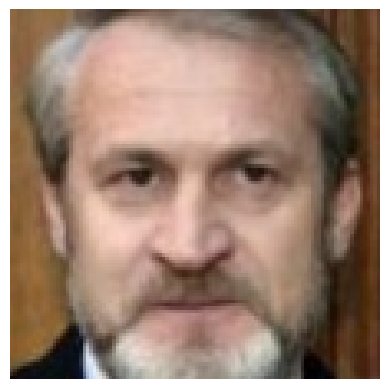

In [ ]:
idx = min(3, len(quick_images) - 1)
image_to_save = quick_images[idx]
image_bgr = cv2.cvtColor(image_to_save, cv2.COLOR_RGB2BGR) if COLOR_ORDER == 'RGB' else image_to_save
save_path = output_dir / f'lfw_image_{idx}.png'
if not cv2.imwrite(str(save_path), image_bgr):
    raise OSError(f'이미지 저장 실패: {save_path}')
print('Image saved to:', save_path)
from matplotlib import pyplot as plt
plt.imshow(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
plt.axis('off')


## 3. Extract Face Embeddings

In [ ]:
# 이미지 채널 순서는 위 COLOR_ORDER로 고정하고 ONNX에서도 같은 텐서를 사용합니다.
image_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((112, 112)),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3),
])


@torch.inference_mode()
def extract_embeddings(net, encoded_images):
    net.eval()
    outputs = []
    for start in range(0, len(encoded_images), BATCH_SIZE):
        batch = torch.stack([image_transform(decode_lfw(b))
                             for b in encoded_images[start:start + BATCH_SIZE]]).to(device)
        features = net(batch).reshape(batch.shape[0], -1).float()
        outputs.append(F.normalize(features, p=2, dim=1).cpu().numpy())
    return np.concatenate(outputs, axis=0)


quick_bins = lfw_bins[:2 * QUICK_PAIRS]
feature_maps = extract_embeddings(baseline_model, quick_bins)
feature_maps_mod = extract_embeddings(modified_model, quick_bins)
print('embedding shape:', feature_maps.shape)
print('baseline ↔ modified embedding cosine mean:',
      float(np.sum(feature_maps * feature_maps_mod, axis=1).mean()))
print('소량 샘플의 유사도를 전체 LFW 정확도로 해석하지 않습니다.')


embedding shape: (32, 512)
baseline ↔ modified embedding cosine mean: 1.0
소량 샘플의 유사도를 전체 LFW 정확도로 해석하지 않습니다.


In [ ]:
# 전체 LFW accuracy: 실제 same/different 라벨을 이용하고, 각 fold의 train에서만 threshold를 고릅니다.
def lfw_verification(embeddings, issame):
    scores = np.sum(embeddings[0::2] * embeddings[1::2], axis=1)
    labels = np.asarray(issame, dtype=bool)
    if len(scores) != len(labels) or len(labels) < 10:
        raise ValueError('10-fold verification에는 올바른 쌍과 라벨이 필요합니다.')
    thresholds = np.linspace(-1.0, 1.0, 2001)
    fold_accuracy = []
    for train_idx, test_idx in KFold(n_splits=10, shuffle=False).split(scores):
        train_predictions = scores[train_idx, None] >= thresholds[None, :]
        accuracy = (train_predictions == labels[train_idx, None]).mean(axis=0)
        threshold = thresholds[int(np.argmax(accuracy))]
        fold_accuracy.append(np.mean((scores[test_idx] >= threshold) == labels[test_idx]))
    return float(np.mean(fold_accuracy)), float(np.std(fold_accuracy))


if RUN_FULL_LFW:
    for name, candidate in [('baseline', baseline_model), ('exact', exact_model),
                            ('prelu_approx', modified_model)]:
        full_features = extract_embeddings(candidate, lfw_bins)
        mean, std = lfw_verification(full_features, lfw_issame)
        print(f'{name}: LFW 10-fold accuracy = {mean:.4f} ± {std:.4f}')
else:
    print('전체 LFW 검증 생략 (RUN_FULL_LFW=False).')


전체 LFW 검증 생략 (RUN_FULL_LFW=False).


## 4. Visualize the Embedding Space

Use t-SNE only as a qualitative view of the extracted embeddings. Verification performance is evaluated separately from this visualization.

In [ ]:
# t-SNE는 임베딩 시각화이며 identity 분류/verification accuracy가 아닙니다.
pair_status = np.repeat(np.where(lfw_issame[:QUICK_PAIRS], 'same pair', 'different pair'), 2)
for name, features in [('baseline', feature_maps), ('prelu_approx', feature_maps_mod)]:
    points = TSNE(n_components=2, perplexity=min(10, len(features) - 1),
                  max_iter=500, init='pca', learning_rate='auto', random_state=0
                  ).fit_transform(features)
    fig = px.scatter(x=points[:, 0], y=points[:, 1], color=pair_status,
                     title=f'{name} / LFW sampled pairs (not person IDs)')
    fig.show()


## 5. Cosine-Similarity Retrieval with FAISS

Search for nearby normalized embeddings using cosine similarity. This section demonstrates retrieval behavior and is not used as the LFW verification accuracy metric.

In [ ]:
# FAISS: 자기 자신(0번)을 제외한 유사도 검색. 정확도 지표는 아닙니다.
for name, features in [('baseline', feature_maps), ('prelu_approx', feature_maps_mod)]:
    vectors = np.ascontiguousarray(features, dtype=np.float32).copy()
    faiss.normalize_L2(vectors)
    index = faiss.IndexFlatIP(vectors.shape[1])
    index.add(vectors)
    top_k = min(6, len(vectors) - 1)
    scores, ids = index.search(vectors[0:1], top_k + 1)
    neighbors = [(int(i), float(s)) for i, s in zip(ids[0], scores[0]) if i != 0][:top_k]
    print(name, 'query=0 nearest (index, cosine):', neighbors)


baseline query=0 nearest (index, cosine): [(1, 0.6396869421005249), (30, 0.10753776878118515), (15, 0.08958306163549423), (13, 0.08958306163549423), (28, 0.07788300514221191), (27, 0.07788300514221191)]
prelu_approx query=0 nearest (index, cosine): [(1, 0.6396868228912354), (30, 0.10753810405731201), (15, 0.08958310633897781), (13, 0.08958310633897781), (28, 0.07788286358118057), (27, 0.07788286358118057)]


## 6. Export the Converted Model to ONNX

In [ ]:
# Python/Colab에서만 수행하는 ONNX export입니다. NPU SDK/보드 실행은 포함하지 않습니다.
onnx_path = output_dir / 'arcface_prelu_approx.onnx'
if RUN_ONNX:
    import onnx
    export_model = deepcopy(modified_model).cpu().eval()
    dummy = torch.randn(1, 3, 112, 112, dtype=torch.float32)
    torch.onnx.export(export_model, dummy, str(onnx_path),
                      input_names=['input'], output_names=['output'],
                      opset_version=11, do_constant_folding=True, dynamo=False)
    onnx_model = onnx.load(str(onnx_path))
    onnx.checker.check_model(onnx_model)
    print('ONNX saved:', onnx_path)
else:
    print('ONNX export 생략 (RUN_ONNX=False).')


/tmp/ipykernel_1489/1832368337.py:7: DeprecationWarning:

You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html



ONNX saved: /content/arcface_test/arcface_prelu_approx.onnx


### Inspect the Exported ONNX Graph

In [ ]:
if RUN_ONNX:
    print('Input:', onnx_model.graph.input[0].name)
    print('Output:', onnx_model.graph.output[0].name)
    print('ONNX operators:', Counter(node.op_type for node in onnx_model.graph.node))
    if RUN_NETRON:
        import subprocess, sys
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'netron', 'portpicker'], check=True)
        import netron, portpicker
        from google.colab import output
        port = portpicker.pick_unused_port()
        netron.start(str(onnx_path), port, browse=False)
        output.serve_kernel_port_as_iframe(port, height='800')


Input: input
Output: output
ONNX operators: Counter({'Conv': 102, 'Relu': 49, 'Mul': 49, 'Add': 49, 'Sub': 25, 'BatchNormalization': 25, 'GlobalAveragePool': 24, 'Sigmoid': 24})


### Validate PyTorch and ONNX Output Consistency

In [ ]:
# PyTorch와 ONNXRuntime에 동일한 전처리 텐서를 넣고 직접 비교합니다.
if RUN_ONNX:
    import onnxruntime as ort
    x = image_transform(quick_images[0]).unsqueeze(0).float()
    with torch.inference_mode():
        pt_out = export_model(x).reshape(1, -1).numpy()
    session = ort.InferenceSession(str(onnx_path), providers=['CPUExecutionProvider'])
    ort_out = session.run(None, {session.get_inputs()[0].name: x.numpy()})[0].reshape(1, -1)
    diff = np.abs(pt_out - ort_out)
    cosine = float(np.sum(F.normalize(torch.from_numpy(pt_out), dim=1).numpy() *
                          F.normalize(torch.from_numpy(ort_out), dim=1).numpy()))
    print('PyTorch vs ONNXRuntime max_abs:', float(diff.max()))
    print('PyTorch vs ONNXRuntime cosine:', cosine)
else:
    print('ONNX 비교 생략 (RUN_ONNX=False).')


PyTorch vs ONNXRuntime max_abs: 1.817941665649414e-06
PyTorch vs ONNXRuntime cosine: 1.0


## 7. Prepare ENLIGHT Calibration Data

In [ ]:
# COLOR_ORDER와 전처리를 그대로 사용
# 우선 LFW 이미지 100장으로 변환·양자화 동작을 확인
# 최종 LFW 정확도 평가에는 별도의 대표 calibration 데이터를 사용 권장

import zipfile

CALIB_COUNT = 100
calib_dir = output_dir / "arcface_calib_npy"
calib_dir.mkdir(parents=True, exist_ok=True)

if len(lfw_bins) < CALIB_COUNT:
    raise ValueError(f"Calibration 이미지 부족: {len(lfw_bins)}장")

# 재실행 시 이전 calibration 파일이 섞이지 않도록 정리
for old_file in calib_dir.glob("*.npy"):
    old_file.unlink()

# LFW 전체에서 100장을 고정된 시드로 추출
rng = np.random.default_rng(42)
sample_indices = rng.choice(
    len(lfw_bins), size=CALIB_COUNT, replace=False
)

max_abs = 0.0

for i, image_idx in enumerate(sample_indices):
    image = decode_lfw(lfw_bins[int(image_idx)])

    # 기존 ArcFace 추론과 동일한 전처리
    # [3, 112, 112], float32, normalization 적용 완료
    x = image_transform(image).numpy().astype(np.float32)

    if x.shape != (3, 112, 112):
        raise ValueError(f"잘못된 입력 shape: {x.shape}")
    if not np.isfinite(x).all():
        raise ValueError(f"NaN 또는 Inf 발견: {image_idx}")

    np.save(calib_dir / f"calib_{i:04d}.npy", x)
    max_abs = max(max_abs, float(np.abs(x).max()))

# ENLIGHT CustomNPY의 input quantization scale
if max_abs == 0:
    raise ValueError("Calibration 데이터의 모든 값이 0입니다.")

iqscl = 127.0 / max_abs

# Docker로 옮길 수 있도록 데이터와 scale을 ZIP으로 묶기
scale_path = output_dir / "arcface_calib_iqscl.txt"
scale_path.write_text(f"{iqscl:.12g}\n")

zip_path = output_dir / "arcface_calib_npy.zip"

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for npy_path in sorted(calib_dir.glob("*.npy")):
        zf.write(npy_path, arcname=f"calib_npy/{npy_path.name}")
    zf.write(scale_path, arcname="arcface_calib_iqscl.txt")

print(f"Calibration images: {CALIB_COUNT}")
print(f"Input shape: {np.load(calib_dir / 'calib_0000.npy').shape}")
print(f"COLOR_ORDER: {COLOR_ORDER}")
print(f"Input max_abs: {max_abs:.8f}")
print(f"Input quantization scale: {iqscl:.12g}")
print(f"ZIP saved: {zip_path}")

Calibration images: 100
Input shape: (3, 112, 112)
COLOR_ORDER: BGR
Input max_abs: 1.00000000
Input quantization scale: 127
ZIP saved: /content/arcface_test/arcface_calib_npy.zip


### Prepare 100-Pair Verification Data

In [ ]:
# LFW 동일인·타인 판정 검증용 데이터 생성

import csv
import zipfile

assert COLOR_ORDER == "BGR", "Calibration과 동일한 COLOR_ORDER를 사용해야 합니다."
assert len(sample_indices) == CALIB_COUNT
assert len(lfw_bins) == 2 * len(lfw_issame)

labels = np.asarray(lfw_issame, dtype=bool)

# 실제 calibration에 사용한 이미지 인덱스를 재사용
calib_indices = set(map(int, sample_indices))

# 두 이미지 모두 calibration에 사용되지 않은 LFW 쌍만 선택
available_pairs = np.array([
    p for p in range(len(labels))
    if 2 * p not in calib_indices
    and 2 * p + 1 not in calib_indices
])

same_pairs = available_pairs[labels[available_pairs]]
diff_pairs = available_pairs[~labels[available_pairs]]

rng = np.random.default_rng(2026)
rng.shuffle(same_pairs)
rng.shuffle(diff_pairs)

assert len(same_pairs) >= 300 and len(diff_pairs) >= 300

# 테스트 100쌍: 동일인 50쌍 + 타인 50쌍
test_pairs = np.concatenate([
    same_pairs[:50],
    diff_pairs[:50],
])

# 임계값 결정용 500쌍: 테스트 데이터와 겹치지 않음
val_pairs = np.concatenate([
    same_pairs[50:300],
    diff_pairs[50:300],
])

rng.shuffle(test_pairs)
rng.shuffle(val_pairs)

assert not set(test_pairs) & set(val_pairs)


def get_pair_bins(pair_indices):
    return [
        lfw_bins[2 * int(p) + offset]
        for p in pair_indices
        for offset in (0, 1)
    ]


def get_pair_scores(embeddings):
    return np.sum(
        embeddings[0::2] * embeddings[1::2],
        axis=1,
    )


# 1. 원본 모델로 판정 임계값 결정
val_embeddings = extract_embeddings(
    baseline_model,
    get_pair_bins(val_pairs),
)

val_scores = get_pair_scores(val_embeddings)
val_labels = labels[val_pairs]

thresholds = np.linspace(-1.0, 1.0, 2001)

val_accuracies = (
    (val_scores[:, None] >= thresholds[None, :])
    == val_labels[:, None]
).mean(axis=0)

threshold = float(thresholds[np.argmax(val_accuracies)])


# 2. 원본 모델의 테스트 100쌍 결과
test_embeddings = extract_embeddings(
    baseline_model,
    get_pair_bins(test_pairs),
)

test_scores = get_pair_scores(test_embeddings)
test_labels = labels[test_pairs]

baseline_accuracy = np.mean(
    (test_scores >= threshold) == test_labels
)


# 3. INT8 Simulator에 넣을 전처리 완료 NPY 저장
eval_dir = output_dir / "lfw_100pairs_eval"
npy_dir = eval_dir / "test_npy"
npy_dir.mkdir(parents=True, exist_ok=True)

rows = []

for pair_no, pair_idx in enumerate(test_pairs):
    filenames = []

    for offset in (0, 1):
        filename = f"test_{2 * pair_no + offset:04d}.npy"

        image = decode_lfw(
            lfw_bins[2 * int(pair_idx) + offset]
        )

        # Calibration과 완전히 동일한 전처리
        x = image_transform(image).numpy().astype(np.float32)

        assert x.shape == (3, 112, 112)
        assert np.isfinite(x).all()

        np.save(npy_dir / filename, x)
        filenames.append(filename)

    rows.append({
        "pair_id": pair_no,
        "lfw_pair_index": int(pair_idx),
        "is_same": int(labels[pair_idx]),
        "file_a": filenames[0],
        "file_b": filenames[1],
        "baseline_score": float(test_scores[pair_no]),
    })


# 4. 정답 라벨·원본 점수·임계값 저장
with (eval_dir / "pairs.csv").open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)

(eval_dir / "threshold.txt").write_text(
    f"{threshold:.12g}\n"
)


# 5. Docker로 옮길 ZIP 생성
zip_path = output_dir / "lfw_100pairs_eval.zip"

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for path in sorted(eval_dir.rglob("*")):
        if path.is_file():
            zf.write(path, arcname=path.relative_to(eval_dir))


print(f"Calibration images excluded: {len(calib_indices)}")
print(f"Validation pairs: {len(val_pairs)}")
print(f"Test pairs: {len(test_pairs)}")
print(f"Test NPY files: {len(list(npy_dir.glob('*.npy')))}")
print(f"Threshold: {threshold:.6f}")
print(f"Original accuracy: {baseline_accuracy:.2%}")
print(f"ZIP saved: {zip_path}")

Calibration images excluded: 100
Validation pairs: 500
Test pairs: 100
Test NPY files: 200
Threshold: 0.215000
Original accuracy: 99.00%
ZIP saved: /content/arcface_test/lfw_100pairs_eval.zip


### Prepare 1,000-Pair Verification Data

In [ ]:
# ============================================================
# LFW 1,000-pair validation
# 기존 calibration / validation / 100-pair test와 분리
# 기존 500쌍에서 결정한 threshold 그대로 사용
# ============================================================

import csv
import hashlib
import zipfile

TEST_PAIRS_PER_CLASS = 500
TEST_PAIR_COUNT = TEST_PAIRS_PER_CLASS * 2

large_eval_dir = output_dir / "lfw_1000pairs_eval"
large_npy_dir = large_eval_dir / "test_npy"
large_npy_dir.mkdir(parents=True, exist_ok=True)

labels = np.asarray(lfw_issame, dtype=bool)

assert len(lfw_bins) == 2 * len(labels)
assert len(sample_indices) == CALIB_COUNT
assert len(val_pairs) == 500
assert len(test_pairs) == 100


# ------------------------------------------------------------
# 1. 이미지 중복 검사
# ------------------------------------------------------------

def image_hash(image_idx):
    encoded = lfw_bins[int(image_idx)]
    return hashlib.sha256(encoded).digest()


# Calibration에 사용한 이미지 제외
used_hashes = {
    image_hash(idx)
    for idx in sample_indices
}

# 이전 threshold 결정용 500쌍과 테스트 100쌍도 제외
previous_pairs = np.concatenate([
    val_pairs,
    test_pairs,
])

for pair_idx in previous_pairs:
    used_hashes.add(image_hash(2 * int(pair_idx)))
    used_hashes.add(image_hash(2 * int(pair_idx) + 1))


def select_new_pairs(candidates, count):
    selected = []

    for pair_idx in candidates:
        pair_idx = int(pair_idx)

        hash_a = image_hash(2 * pair_idx)
        hash_b = image_hash(2 * pair_idx + 1)

        # 이전 데이터 또는 이번 테스트에 이미 사용한 이미지 제외
        if hash_a in used_hashes or hash_b in used_hashes:
            continue

        selected.append(pair_idx)

        used_hashes.add(hash_a)
        used_hashes.add(hash_b)

        if len(selected) == count:
            break

    if len(selected) < count:
        raise RuntimeError(
            f"테스트 쌍 부족: {len(selected)}/{count}\n"
            "중복 제외 후 사용 가능한 LFW 쌍을 확인하세요."
        )

    return np.asarray(selected, dtype=np.int64)


# 기존 100쌍: [:50]
# 기존 validation 500쌍: [50:300]
# 새로운 테스트는 [300:]부터 선택
large_same_pairs = select_new_pairs(
    same_pairs[300:],
    TEST_PAIRS_PER_CLASS,
)

large_diff_pairs = select_new_pairs(
    diff_pairs[300:],
    TEST_PAIRS_PER_CLASS,
)

large_test_pairs = np.concatenate([
    large_same_pairs,
    large_diff_pairs,
])

rng = np.random.default_rng(2027)
rng.shuffle(large_test_pairs)

assert len(large_test_pairs) == TEST_PAIR_COUNT

# 이전 검증·테스트 쌍과 인덱스 중복이 없는지 확인
assert not (
    set(map(int, large_test_pairs))
    & set(map(int, previous_pairs))
)

print("New test pairs:", len(large_test_pairs))
print("Same pairs:", int(labels[large_test_pairs].sum()))
print("Different pairs:", int((~labels[large_test_pairs]).sum()))


# ------------------------------------------------------------
# 2. 원본 PyTorch 모델로 1,000쌍 추론
# ------------------------------------------------------------

large_test_embeddings = extract_embeddings(
    baseline_model,
    get_pair_bins(large_test_pairs),
)

large_test_scores = get_pair_scores(
    large_test_embeddings
)

large_test_labels = labels[large_test_pairs]

# 기존 validation 500쌍에서 결정한 threshold 재사용
large_baseline_predictions = (
    large_test_scores >= threshold
)

large_baseline_accuracy = np.mean(
    large_baseline_predictions == large_test_labels
)

print(f"Fixed threshold: {threshold:.6f}")
print(f"Original accuracy: {large_baseline_accuracy:.2%}")


# ------------------------------------------------------------
# 3. INT8 Simulator 입력용 NPY 2,000개 저장
# ------------------------------------------------------------

# 재실행 시 이전 파일이 섞이지 않도록 정리
for old_file in large_npy_dir.glob("test_*.npy"):
    old_file.unlink()

large_rows = []

for pair_no, pair_idx in enumerate(large_test_pairs):
    filenames = []

    for offset in (0, 1):
        image_idx = 2 * int(pair_idx) + offset
        filename = f"test_{2 * pair_no + offset:04d}.npy"

        image = decode_lfw(lfw_bins[image_idx])

        # Calibration / 원본 추론과 동일한 전처리
        x = image_transform(image).numpy().astype(np.float32)

        if x.shape != (3, 112, 112):
            raise ValueError(
                f"{filename}: 잘못된 입력 shape {x.shape}"
            )

        if not np.isfinite(x).all():
            raise ValueError(
                f"{filename}: NaN 또는 Inf 발견"
            )

        np.save(large_npy_dir / filename, x)
        filenames.append(filename)

    large_rows.append({
        "pair_id": pair_no,
        "lfw_pair_index": int(pair_idx),
        "is_same": int(labels[pair_idx]),
        "file_a": filenames[0],
        "file_b": filenames[1],
        "baseline_score": float(large_test_scores[pair_no]),
    })


# ------------------------------------------------------------
# 4. 정답 라벨 / 원본 점수 / 임계값 저장
# ------------------------------------------------------------

with (large_eval_dir / "pairs.csv").open(
    "w", newline=""
) as f:
    writer = csv.DictWriter(
        f,
        fieldnames=list(large_rows[0]),
    )
    writer.writeheader()
    writer.writerows(large_rows)

(large_eval_dir / "threshold.txt").write_text(
    f"{threshold:.12g}\n"
)


# ------------------------------------------------------------
# 5. Docker 전송용 ZIP 생성
# ------------------------------------------------------------

large_zip_path = output_dir / "lfw_1000pairs_eval.zip"

with zipfile.ZipFile(
    large_zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED,
) as zf:

    for path in sorted(large_eval_dir.rglob("*")):
        if path.is_file():
            zf.write(
                path,
                arcname=path.relative_to(large_eval_dir),
            )


print()
print("=" * 55)
print("LFW 1,000-pair dataset ready")
print("=" * 55)

print(f"Test pairs        : {len(large_test_pairs)}")
print(f"Test NPY files    : {len(list(large_npy_dir.glob('*.npy')))}")
print(f"Fixed threshold   : {threshold:.6f}")
print(f"Original accuracy : {large_baseline_accuracy:.2%}")
print(f"ZIP saved         : {large_zip_path}")
print(f"ZIP size          : {large_zip_path.stat().st_size / 1024**2:.1f} MiB")

New test pairs: 1000
Same pairs: 500
Different pairs: 500
Fixed threshold: 0.215000
Original accuracy: 99.50%

LFW 1,000-pair dataset ready
Test pairs        : 1000
Test NPY files    : 2000
Fixed threshold   : 0.215000
Original accuracy : 99.50%
ZIP saved         : /content/arcface_test/lfw_1000pairs_eval.zip
ZIP size          : 83.3 MiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>